# WaniKani Personalized Review Recommender
### Which kanji cards will be hard *for me*?
#### Because kanji is freaking difficult

I study Japanese with [WaniKani](https://www.wanikani.com/), a spaced-repetition (SRS) app for kanji.
Some cards keep tripping me up and fall back down the SRS levels. The goal of this project is to
predict which cards will be hard for me **using only what is known about a card before I struggle with it**,
so I can give those cards extra attention early.

**Contents**
1. Load my data from the WaniKani API (with local caching)
2. Feature engineering: card properties that do **not** depend on my past answers
3. Label: is the card "hard for me"?
4. EDA
5. Train models and compare them against a baseline
6. Evaluate: ROC-AUC, confusion matrix, precision / recall
7. Ranked list of cards to review with extra care
8. Limitations and next steps

## Step 1. Setup

The API token is read from the `WANIKANI_TOKEN` environment variable, so it never ends up in the notebook or on GitHub.
Get a read-only token at WaniKani → Settings → API Tokens.

In [1]:
import os, json, requests, getpass
os.environ["WANIKANI_TOKEN"] = getpass.getpass("WaniKani token: ")
from datetime import datetime, timezone

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

API_KEY = os.environ.get("WANIKANI_TOKEN")
BASE_URL = "https://api.wanikani.com/v2"
HEADERS = {"Authorization": f"Bearer {API_KEY}", "Wanikani-Revision": "20170710"}
CACHE = "wanikani_cache"
RANDOM_STATE = 42

## Step 2. Load data from WaniKani

Three endpoints are needed:
- **subjects**: the cards themselves (radicals, kanji, vocabulary)
- **review_statistics**: how many times I answered each card correctly or incorrectly
- **assignments**: my progress on each card (SRS stage, when I started it)

Responses are paginated, so the loader follows `next_url` until the end. Results are cached as JSON
so the API is called only once.

In [2]:
os.makedirs(CACHE, exist_ok=True)

def fetch_all(endpoint, params=None):
    """Fetch every page of a WaniKani collection endpoint."""
    if not API_KEY:
        raise RuntimeError("Set the WANIKANI_TOKEN environment variable first.")
    url, results = f"{BASE_URL}/{endpoint}", []
    while url:
        resp = requests.get(url, headers=HEADERS, params=params, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        results.extend(data.get("data", []))
        url = data.get("pages", {}).get("next_url")
        params = None  # next_url already contains the query string
    return results

def load(name, fetch_fn):
    path = os.path.join(CACHE, f"{name}.json")
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            data = json.load(f)
        print(f"{name}: {len(data)} items (from cache)")
        return data
    data = fetch_fn()
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False)
    print(f"{name}: {len(data)} items (downloaded)")
    return data

subjects     = load("subjects",    lambda: fetch_all("subjects"))
review_stats = load("rev_stats",   lambda: fetch_all("review_statistics"))
assignments  = load("assignments", lambda: fetch_all("assignments", {"started": "true"}))

subjects: 9452 items (downloaded)
rev_stats: 1756 items (downloaded)
assignments: 1756 items (downloaded)


## Step 3. Features and label

**Avoiding target leakage.** The label below is built from my error rates. If error rates (or anything driven
by them, such as the current SRS stage or the number of reviews) were also used as features, the model would
simply recompute the label and look perfect without learning anything. So the features describe **the card itself**
plus how long I have been studying it, nothing about how I answered.

| Feature | Meaning |
|---|---|
| `subjectType` | 0 = radical, 1 = kanji, 2 = vocabulary |
| `level` | WaniKani level where the card appears (1–60) |
| `nChars` | number of characters |
| `nComponents` | how many radicals / kanji the card is built from |
| `nMeanings` | number of accepted meanings |
| `nReadings` | number of readings |
| `nVisuallySimilar` | kanji that look similar (a classic source of confusion) |
| `nUsedIn` | how many other cards use this one as a component |
| `daysSinceStarted` | how long I have been studying the card |

**Label `isHard`**: 1 if the card's average error rate (meaning + reading) is at or above my median, 0 otherwise.
A median split keeps the classes balanced.

In [3]:
TYPE_MAP = {"radical": 0, "kanji": 1, "vocabulary": 2, "kana_vocabulary": 2}

subj_by_id  = {s["id"]: s for s in subjects}
stats_by_id = {s["data"]["subject_id"]: s["data"] for s in review_stats}
asgn_by_id  = {a["data"]["subject_id"]: a["data"] for a in assignments}
now = datetime.now(timezone.utc)

def parse_time(ts):
    return datetime.fromisoformat(ts.replace("Z", "+00:00")) if ts else None

rows = []
for sid, asgn in asgn_by_id.items():
    st, subj = stats_by_id.get(sid), subj_by_id.get(sid)
    if not st or not subj:
        continue
    stype = TYPE_MAP.get(subj.get("object"))
    if stype is None:
        continue

    mc, mw = st["meaning_correct"], st["meaning_incorrect"]
    rc, rw = st["reading_correct"], st["reading_incorrect"]
    if mc + mw + rc + rw == 0:
        continue

    d = subj["data"]
    started = parse_time(asgn.get("started_at"))
    rows.append({
        "subject_id": sid,
        "name": d.get("characters") or d.get("slug", str(sid)),
        # features: properties of the card, not of my answers
        "subjectType": stype,
        "level": d.get("level", 0),
        "nChars": len(d.get("characters") or ""),
        "nComponents": len(d.get("component_subject_ids", [])),
        "nMeanings": len(d.get("meanings", [])),
        "nReadings": len(d.get("readings", [])),
        "nVisuallySimilar": len(d.get("visually_similar_subject_ids", [])),
        "nUsedIn": len(d.get("amalgamation_subject_ids", [])),
        "daysSinceStarted": (now - started).days if started else 0,
        # used only for the label and for reporting
        "errorRateMeaning": mw / (mc + mw) if mc + mw else 0.0,
        "errorRateReading": rw / (rc + rw) if rc + rw else 0.0,
        "srs": asgn.get("srs_stage", 0),
    })

df = pd.DataFrame(rows)
df["overallError"] = (df["errorRateMeaning"] + df["errorRateReading"]) / 2

threshold = df["overallError"].median()
df["isHard"] = (df["overallError"] >= threshold).astype(int)

FEATURES = ["subjectType", "level", "nChars", "nComponents", "nMeanings",
            "nReadings", "nVisuallySimilar", "nUsedIn", "daysSinceStarted"]
TARGET = "isHard"

print(f"Median error rate: {threshold:.2%}")
print(f"Dataset: {len(df)} cards | hard: {df[TARGET].sum()} | not hard: {(df[TARGET] == 0).sum()}")
df.head()

Median error rate: 5.00%
Dataset: 1752 cards | hard: 878 | not hard: 874


,subject_id,name,subjectType,level,nChars,nComponents,nMeanings,nReadings,nVisuallySimilar,nUsedIn,daysSinceStarted,errorRateMeaning,errorRateReading,srs,overallError,isHard
0,20,山,0,1,1,0,1,0,0,29,1188,0.000000,0.0,9,0.000000,0
1,6,亅,0,1,1,0,1,0,0,5,1188,0.176471,0.0,6,0.088235,1
2,22,日,0,1,1,0,1,0,0,81,1188,0.000000,0.0,9,0.000000,0
3,1,一,0,1,1,0,1,0,0,68,1188,0.000000,0.0,9,0.000000,0
4,12,入,0,1,1,0,1,0,0,3,1188,0.083333,0.0,9,0.041667,0


## Step 4. EDA

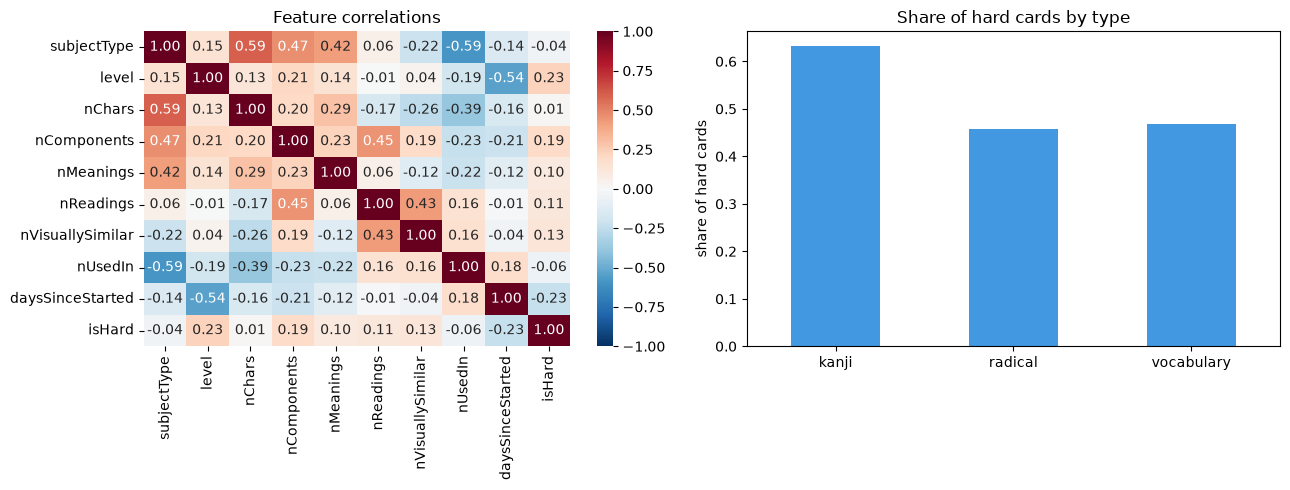

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(df[FEATURES + [TARGET]].corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Feature correlations")

type_names = {0: "radical", 1: "kanji", 2: "vocabulary"}
(df.assign(type=df["subjectType"].map(type_names))
   .groupby("type")[TARGET].mean()
   .plot.bar(ax=axes[1], color="#4299E1"))
axes[1].set_title("Share of hard cards by type")
axes[1].set_ylabel("share of hard cards")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## Step 5. Train models

Three models, compared on the same 80/20 stratified split and with 5-fold cross-validation:
- **Baseline**: always predicts the most frequent class. Any useful model must beat it.
- **Logistic Regression** (with feature scaling, since `daysSinceStarted` is on a much larger scale than the counts)
- **Random Forest**, to catch non-linear patterns

In [5]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f"Train: {len(X_train)} cards | Test: {len(X_test)} cards")

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
for name, m in models.items():
    cv_auc = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc")
    m.fit(X_train, y_train)
    test_auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    results.append({"model": name, "cv_roc_auc": cv_auc.mean(),
                    "cv_std": cv_auc.std(), "test_roc_auc": test_auc})

results = pd.DataFrame(results).set_index("model").round(3)
results

Train: 1401 cards | Test: 351 cards


,cv_roc_auc,cv_std,test_roc_auc
model,,,
Baseline,0.500,0.000,0.500
Logistic Regression,0.724,0.037,0.715
Random Forest,0.717,0.043,0.717


Best model by cross-validation: Logistic Regression


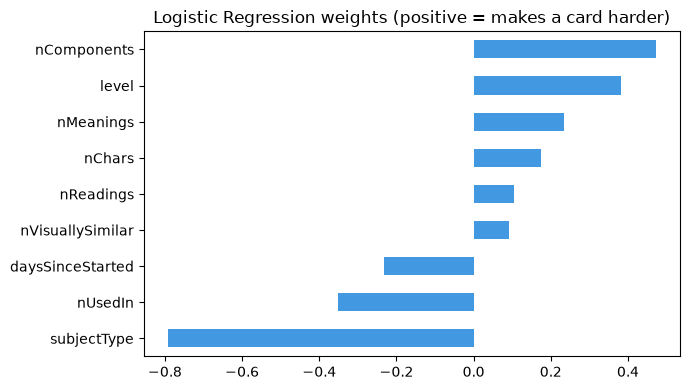

In [6]:
best_name = results.drop("Baseline")["cv_roc_auc"].idxmax()
best = models[best_name]
print(f"Best model by cross-validation: {best_name}")

if best_name == "Logistic Regression":
    weights = best[-1].coef_[0]
    title = "Logistic Regression weights (positive = makes a card harder)"
else:
    weights = best.feature_importances_
    title = "Random Forest feature importance"

pd.Series(weights, index=FEATURES).sort_values().plot.barh(color="#4299E1", figsize=(7, 4))
plt.title(title)
plt.tight_layout()
plt.show()

## Step 6. Evaluate the best model

              precision    recall  f1-score   support

    not hard       0.64      0.70      0.67       175
        hard       0.67      0.61      0.64       176

    accuracy                           0.66       351
   macro avg       0.66      0.66      0.65       351
weighted avg       0.66      0.66      0.65       351



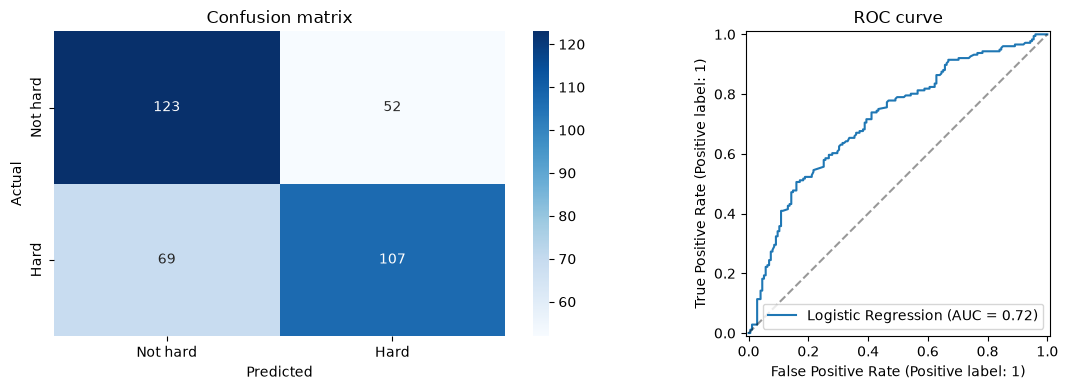

In [7]:
y_pred  = best.predict(X_test)
y_proba = best.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["not hard", "hard"], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Not hard", "Hard"], yticklabels=["Not hard", "Hard"])
axes[0].set_title("Confusion matrix")
axes[0].set_ylabel("Actual")
axes[0].set_xlabel("Predicted")

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name=best_name)
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_title("ROC curve")

plt.tight_layout()
plt.show()

## Step 7. Recommendations

Score every card I am still learning (not yet burned, SRS stage below 9) and rank them by the predicted
probability of being hard. The top of this list is where extra review time pays off most.

In [8]:
df["hardProbability"] = best.predict_proba(df[FEATURES])[:, 1]

recommendations = (df[(df["srs"] > 0) & (df["srs"] < 9)]
                   .sort_values("hardProbability", ascending=False)
                   .reset_index(drop=True))

recommendations["type"] = recommendations["subjectType"].map(type_names)
recommendations[["name", "type", "level", "srs", "overallError", "hardProbability"]].head(20).round(3)

,name,type,level,srs,overallError,hardProbability
0,欠く,vocabulary,42,3,0.161,0.967
1,決,vocabulary,46,6,0.056,0.950
2,顔,kanji,10,3,0.143,0.946
3,床,kanji,7,1,0.250,0.938
4,岸,kanji,11,5,0.204,0.912
5,低,kanji,11,2,0.167,0.910
6,誰,kanji,11,3,0.161,0.909
7,決定する,vocabulary,10,3,0.000,0.906
8,屋,kanji,9,6,0.178,0.905
9,仲間,vocabulary,14,2,0.000,0.904


## Step 8. Limitations and next steps

- **The label describes the past.** `isHard` is based on my error rates up to today, so the model learns which
  kinds of cards *have been* hard for me. The honest next step is a time-based target: save a snapshot of my
  statistics today, download them again in two weeks, and predict which cards get **new** mistakes in between.
  The cell below saves a dated snapshot for that.
- **Small, personal dataset.** Around 1,700 cards from one learner, so the patterns are mine and won't
  necessarily generalise.
- **More features to try**: how similar a card's meaning is to other cards I know, the number of on'yomi vs kun'yomi
  readings, and how many of a kanji's components I have already burned.
- **Web app**: show the ranked queue in a small Streamlit app.

In [9]:
# Save a dated snapshot of review statistics for a future time-based target
snapshot_dir = os.path.join(CACHE, "snapshots")
os.makedirs(snapshot_dir, exist_ok=True)
snapshot_path = os.path.join(snapshot_dir, f"rev_stats_{now:%Y-%m-%d}.json")
with open(snapshot_path, "w", encoding="utf-8") as f:
    json.dump(review_stats, f, ensure_ascii=False)
print(f"Snapshot saved: {snapshot_path}")

Snapshot saved: wanikani_cache\snapshots\rev_stats_2026-10-20.json
